# NMR shielding parameter accuracy at N100

Direct training (01), full fine-tuning (05) and rank-4 ELoRA (06). Analysis: 6 November 2026. The principal comparison uses all 150 held-out test structures, with Si/O scored separately. Validation and N100 fitting scores are stored separately and can be selected with `SPLIT`.

These parameters assess the shielding contribution to NMR lineshape. No experimental referencing or spectrum simulation is performed. The model still predicts the full symmetric tensor and was trained with the original balanced 0e/2e loss.

## Definitions and conventions

The installed Soprano getters are applied to each tensor: `MSIsotropy.get`, `MSAnisotropy.get` and `MSAsymmetry.get`. Fresh ASE objects prevent cached diagonalisation from being reused across reference and prediction.

| Quantity | Definition in the Haeberlen principal-axis ordering | Units |
| --- | --- | --- |
| Isotropic shielding | σiso = (σXX + σYY + σZZ)/3 | ppm |
| Anisotropy | Δσ = σZZ − (σXX + σYY)/2 | ppm |
| Asymmetry | η = (σYY − σXX)/(σZZ − σiso) | Dimensionless |

Z is the principal value furthest from the isotropic mean, Y the closest and X the remaining value. Reduced anisotropy ζσ = σZZ − σiso = 2Δσ/3 is also saved; the headline anisotropy is the unreduced Δσ returned by `MSAnisotropy`. These are shielding parameters. Shift referencing can reverse anisotropy signs and must be handled explicitly before experimental spectrum simulation.

[Soprano NMR tutorial](https://ccp-nc.github.io/soprano/tutorials/05-nmr.html) · [Tensor definitions](https://ccp-nc.github.io/soprano/_autosummary/soprano.nmr.tensor.html) · [Simulation conventions](https://ccp-nc.github.io/soprano/simpson-conventions.html)

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'nmr_helpers').is_dir())
sys.path.insert(0, str(ROOT))
from analysis_helpers.symmetric_transfer_review import load_review, save_figure, LABELS
from analysis_helpers.nmr_parameters import (
    PARAMETERS, NAMES, prepare_parameters, load_parameter_metrics, plot_parameter_rmse,
    plot_parameter_parity, plot_run_parameter_parity, plot_sign_diagnostics,
)
load_review(ROOT)
PARAMETER_DATA = ROOT / 'experiments/symmetric-transfer-N100-data/nmr-parameters'
FIGURES = PARAMETER_DATA / 'figures'
RECOMPUTE_PARAMETERS = False
if RECOMPUTE_PARAMETERS:
    prepare_parameters(ROOT)  # Existing predictions only; no inference or training.
parameter_metrics = load_parameter_metrics(ROOT)
parameter_manifest = json.loads((PARAMETER_DATA / 'manifest.json').read_text())
SPLIT = 'test'
pd.set_option('display.max_columns', 14)
pd.set_option('display.precision', 4)
print('Soprano:', parameter_manifest['soprano_version'])
print('Checkpoint choice: original balanced tensor validation loss, unchanged.')
print('Reference: original DFT ms tensors. Prediction: reconstructed 0e+2e symmetric tensors.')
print('Primary scores retain all atoms and the original signed Haeberlen Delta.')


Soprano: 0.11.4
Checkpoint choice: original balanced tensor validation loss, unchanged.
Reference: original DFT ms tensors. Prediction: reconstructed 0e+2e symmetric tensors.
Primary scores retain all atoms and the original signed Haeberlen Delta.


## Parameter error comparison

All checkpoints were selected using the original tensor validation loss. These new metrics are post-training evaluation, without checkpoint reselection, calibration or sign alignment. Isotropy and anisotropy errors are in ppm; asymmetry errors are dimensionless.

,Method,Element,Parameter,Units,N,RMSE,MAE,R²
0,Direct training,Si,isotropy,ppm,7200,1.5163,0.7378,0.9693
1,Direct training,Si,anisotropy,ppm,7200,20.8414,7.1973,0.7640
2,Direct training,Si,asymmetry,dimensionless,7200,0.1374,0.0992,0.6655
3,Direct training,O,isotropy,ppm,14400,3.0895,1.6401,0.9697
4,Direct training,O,anisotropy,ppm,14400,18.3651,5.1662,0.6577
5,Direct training,O,asymmetry,dimensionless,14400,0.0978,0.0647,0.8024
6,Full fine-tuning,Si,isotropy,ppm,7200,1.0501,0.5753,0.9853
7,Full fine-tuning,Si,anisotropy,ppm,7200,20.6055,6.2903,0.7693
8,Full fine-tuning,Si,asymmetry,dimensionless,7200,0.1184,0.0844,0.7516
9,Full fine-tuning,O,isotropy,ppm,14400,2.5901,1.3808,0.9787


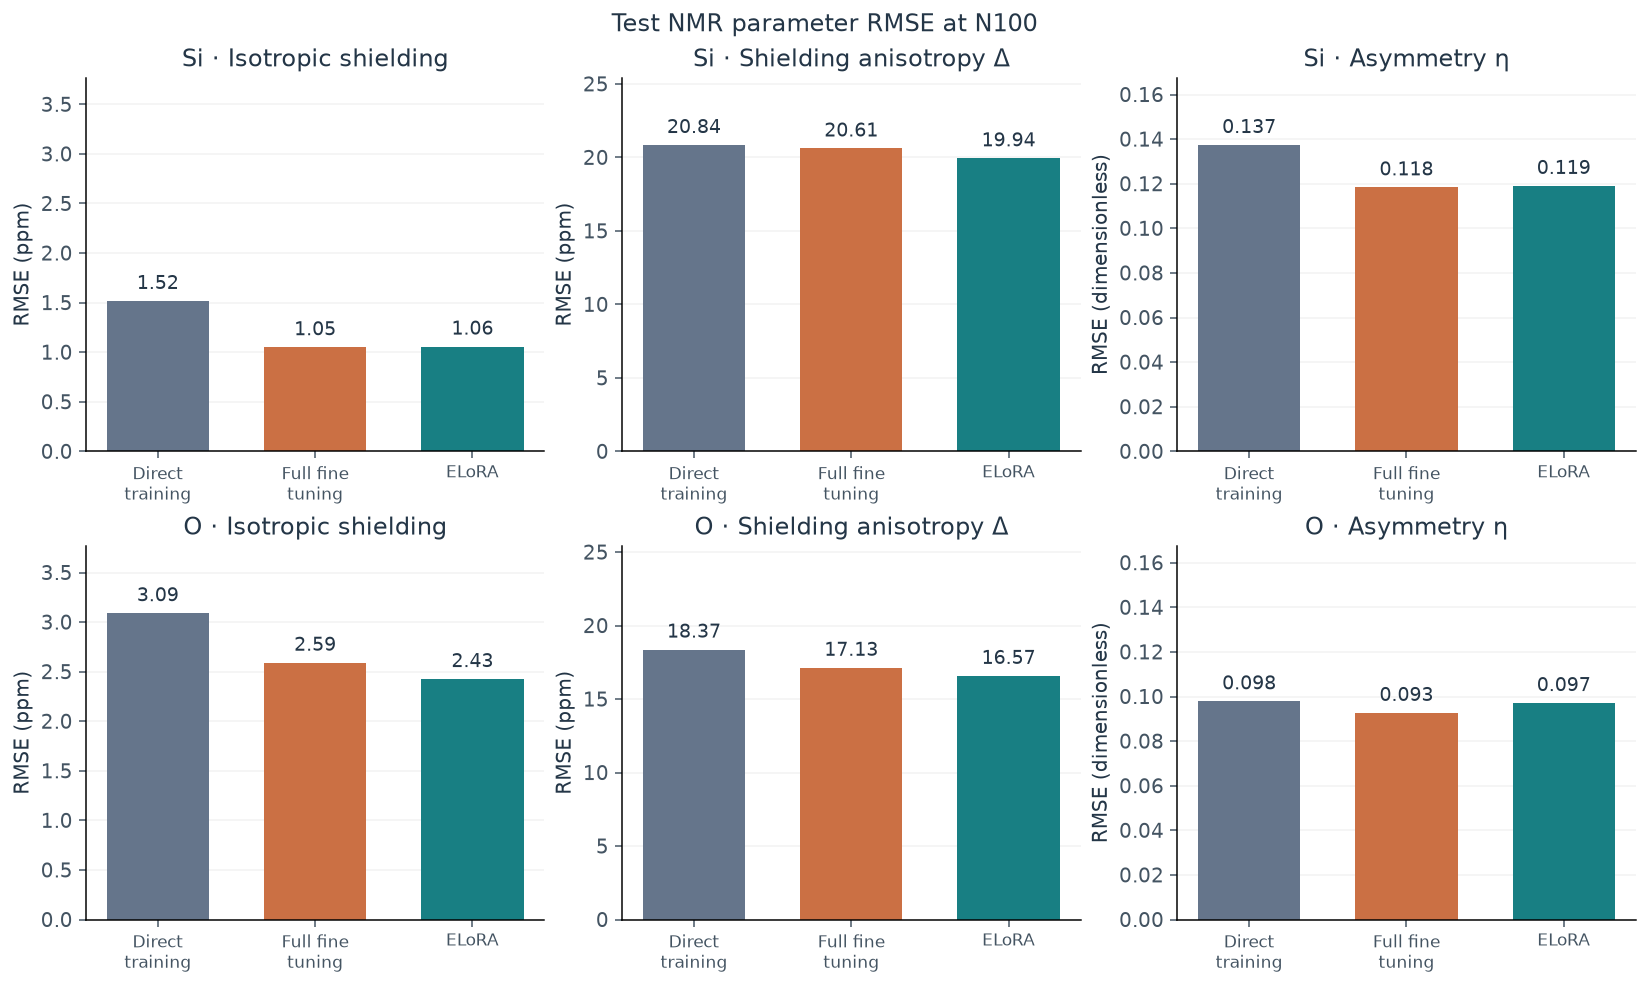

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


In [2]:
selected = parameter_metrics[(parameter_metrics.Split == SPLIT) & parameter_metrics.Parameter.isin(PARAMETERS)]
display(selected[['Method','Element','Parameter','Units','N','RMSE','MAE','R2']].rename(columns={'R2':'R²'}).reset_index(drop=True))
fig = plot_parameter_rmse(parameter_metrics, SPLIT)
save_figure(fig, FIGURES, SPLIT + '-parameter-rmse')
plt.show()


## Anisotropy parity

Each point is one atom prediction. Shared limits across methods include every point. Tiny circular markers follow the established plot style. Red points indicate opposite signs of predicted and DFT anisotropy. These remain in all headline metrics. The opposite-sign population can include Haeberlen principal-axis ordering crossings and genuine tensor errors; the diagnostic below separates these observations from the tensor accuracy claim.

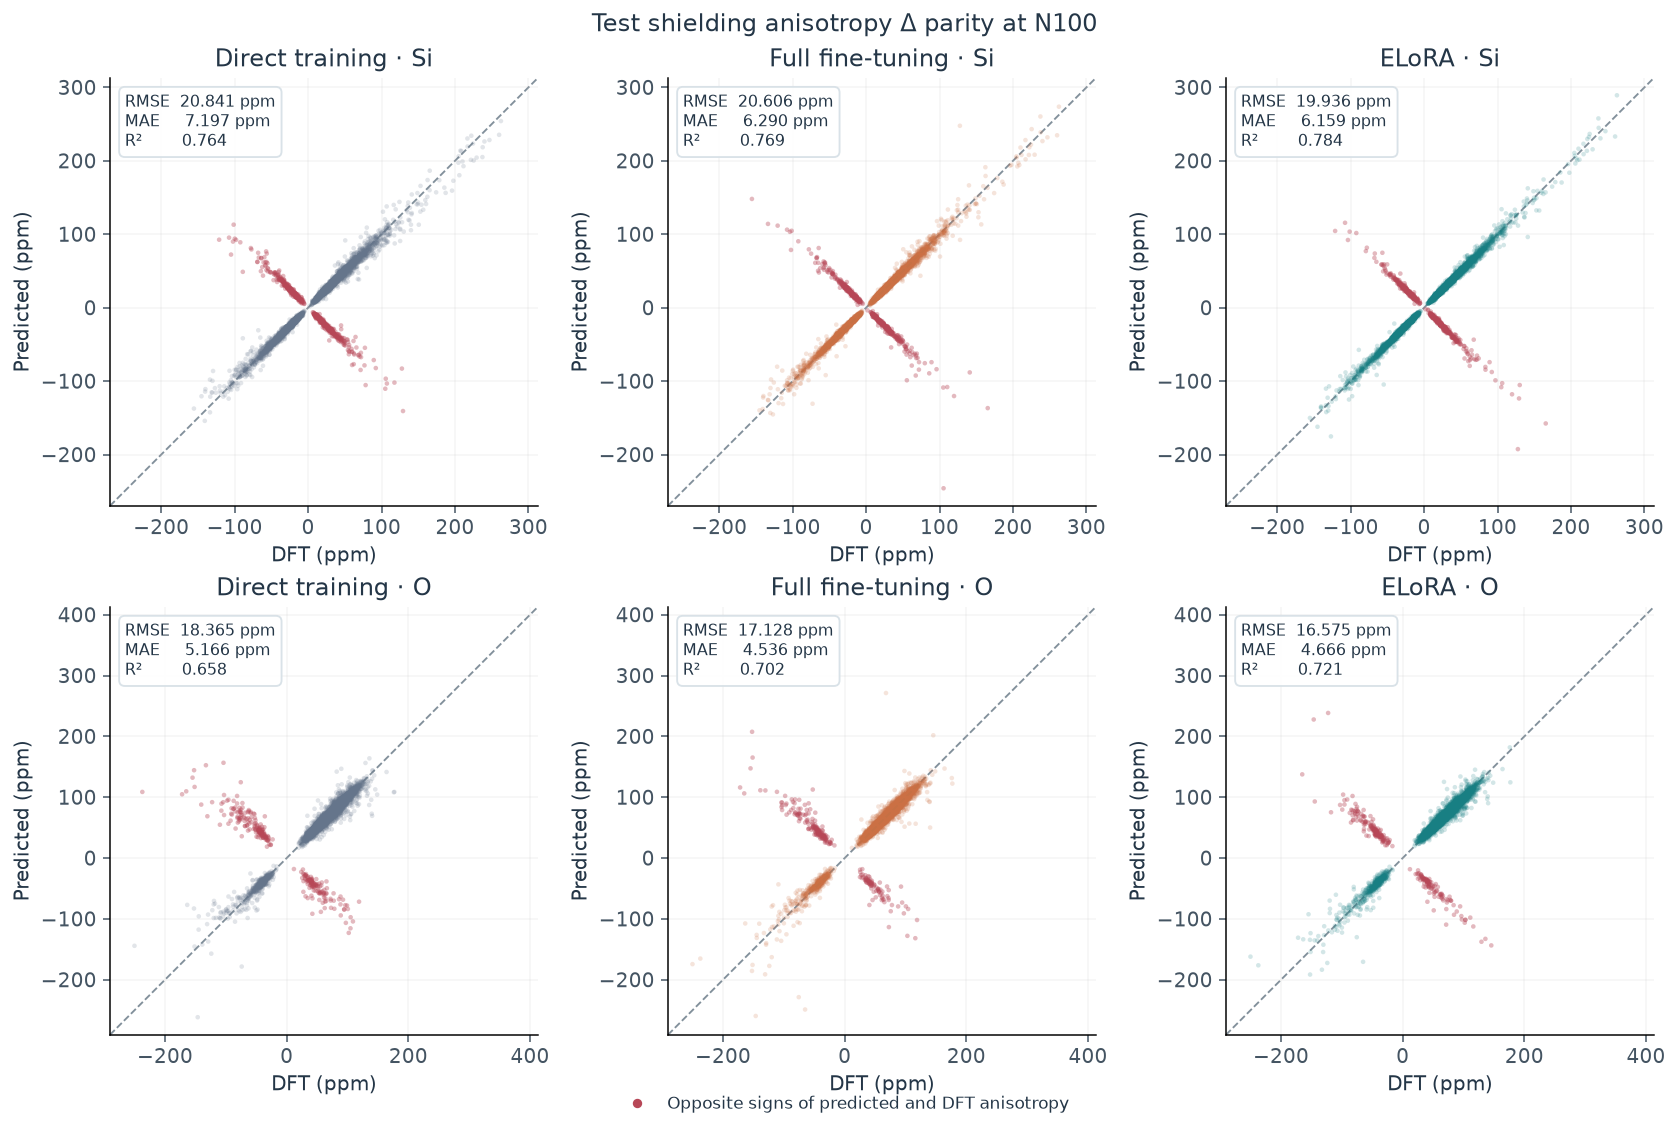

In [3]:
fig = plot_parameter_parity(PARAMETER_DATA, 'anisotropy', SPLIT)
save_figure(fig, FIGURES, SPLIT + '-anisotropy-parity')
plt.show()


## Asymmetry parity

η describes the shape of the symmetric tensor and does not refer to an antisymmetric tensor component. All atoms are retained; no near-isotropic filtering or clipping is applied. The counts of weak-anisotropy cases are reported below.

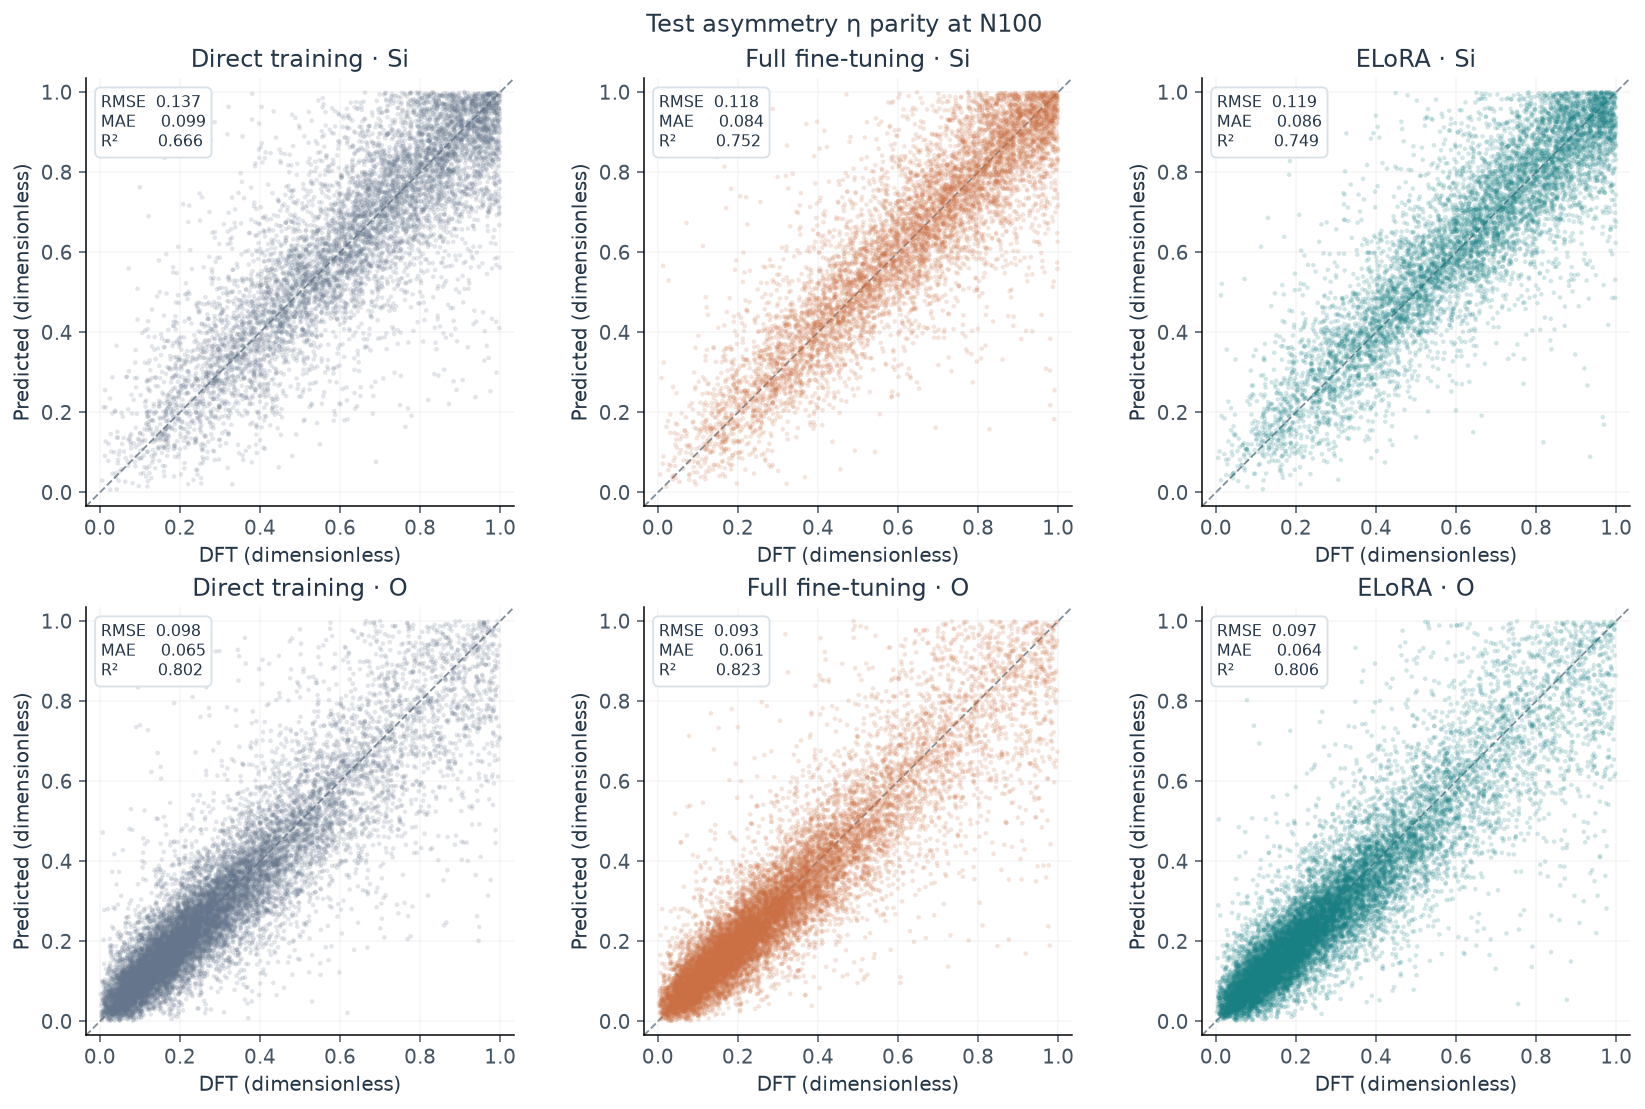

In [4]:
fig = plot_parameter_parity(PARAMETER_DATA, 'asymmetry', SPLIT)
save_figure(fig, FIGURES, SPLIT + '-asymmetry-parity')
plt.show()


## Principal-axis ordering and weak-anisotropy diagnostics

As η approaches 1, the most positive and most negative deviations from isotropy approach equal magnitude. A prediction can cross which one Soprano calls Z, causing signed Δσ to switch sign. This can produce a large Δσ residual even when principal values are relatively close. Not every sign difference is harmless: the table and plot report where they occur, without removing them.

The same-sign-only RMSE is a diagnostic subset, not the headline result. Span Ω = σmax − σmin and the RMSE of the three centred, numerically sorted principal values provide companion shape checks without the signed Haeberlen branch choice. They still omit tensor orientation. Full-tensor errors remain available in the original comparison.

,Method,Element,N,Opposite_sign_count,Opposite_sign_percent,Delta_MSE_from_opposite_sign_percent,Delta_RMSE_same_sign_only_diagnostic,Reference_abs_zeta_min_ppm,Reference_abs_zeta_below_1ppm,Prediction_abs_zeta_below_1ppm
0,Direct training,Si,7200,619,8.5972,96.5163,4.0688,1.2942,0,0
1,Direct training,O,14400,291,2.0208,92.9547,4.9247,7.9344,0,0
2,Full fine-tuning,Si,7200,547,7.5972,97.0980,3.6517,1.2942,0,0
3,Full fine-tuning,O,14400,242,1.6806,91.2618,5.1061,7.9344,0,0
4,ELoRA,Si,7200,562,7.8056,98.0042,2.9332,1.2942,0,0
5,ELoRA,O,14400,259,1.7986,93.1098,4.3904,7.9344,0,0


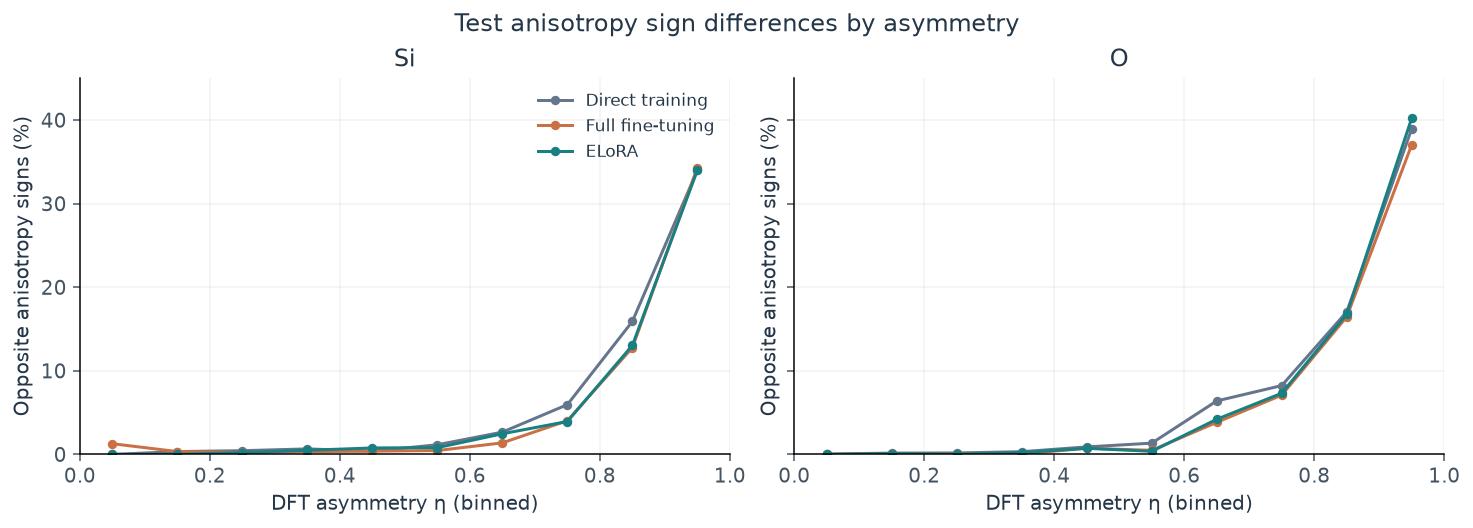

,Method,Element,Span RMSE (ppm),Span MAE (ppm)
0,Direct training,Si,4.7717,2.7740
1,Direct training,O,6.4412,3.5565
2,Full fine-tuning,Si,4.9148,2.2816
3,Full fine-tuning,O,7.0691,3.2610
4,ELoRA,Si,3.6128,2.0537
5,ELoRA,O,5.5814,3.3529


,Method,Element,Centred_principal_value_RMSE_ppm,Centred_principal_value_MAE_ppm
0,Direct training,Si,2.5149,1.4658
1,Direct training,O,3.3604,1.9027
2,Full fine-tuning,Si,2.4771,1.2264
3,Full fine-tuning,O,3.4516,1.7495
4,ELoRA,Si,1.9432,1.1491
5,ELoRA,O,2.9510,1.8024


In [5]:
diagnostics = pd.read_csv(PARAMETER_DATA / 'convention-diagnostics.csv', dtype={'Experiment':str})
view = diagnostics[diagnostics.Split == SPLIT]
display(view[['Method','Element','N','Opposite_sign_count','Opposite_sign_percent',
              'Delta_MSE_from_opposite_sign_percent','Delta_RMSE_same_sign_only_diagnostic',
              'Reference_abs_zeta_min_ppm','Reference_abs_zeta_below_1ppm','Prediction_abs_zeta_below_1ppm']].reset_index(drop=True))
fig = plot_sign_diagnostics(PARAMETER_DATA, SPLIT)
save_figure(fig, FIGURES, SPLIT + '-sign-ordering-diagnostic')
plt.show()
shape = pd.read_csv(PARAMETER_DATA / 'principal-value-metrics.csv',dtype={'Experiment':str})
span = parameter_metrics[(parameter_metrics.Split == SPLIT) & (parameter_metrics.Parameter == 'span')]
display(span[['Method','Element','RMSE','MAE']].rename(columns={'RMSE':'Span RMSE (ppm)','MAE':'Span MAE (ppm)'}).reset_index(drop=True))
display(shape[shape.Split == SPLIT].drop(columns=['Experiment','Split']).reset_index(drop=True))


## Interpretation

Both transfer methods lower all six primary test RMSE quantities relative to direct training. **ELoRA has the lowest shielding-anisotropy RMSE for Si and O. Full fine-tuning has the lowest asymmetry RMSE for both elements.** The Si asymmetry difference between the transfer methods is small (0.11837 versus 0.11900). Full fine-tuning also has the marginally lower Si isotropic RMSE; ELoRA has the lower O isotropic RMSE. The new physical parameter view therefore gives a more nuanced comparison than pooled tensor RMSE alone.

Signed anisotropy RMSEs are around 17–21 ppm. Opposite-sign cases are about 7.6–8.6% of Si and 1.7–2.0% of O predictions and contribute substantially to those squared errors. Keep the unmodified Soprano scores, the sign-ordering diagnostic and the companion shape metrics together. No DFT test atom has |ζσ| below 1 ppm: minimum values are approximately 1.29 ppm for Si and 7.93 ppm for O. Other weak-anisotropy counts and prediction minima are included in the diagnostic table.

These parameters describe intrinsic tensor shape, not principal-axis orientation. They assess the shielding/CSA contribution, not the complete experimental spectrum including other interactions. Single-seed, method-specific learning-rate scope and the original validation-based checkpoint choices are unchanged.

[Isotropic shielding parity](symmetric-transfer-N100-data/nmr-parameters/figures/test-isotropy-parity.png) · [Parameter metrics CSV](symmetric-transfer-N100-data/nmr-parameters/parameter-metrics.csv) · [Largest parameter errors](symmetric-transfer-N100-data/nmr-parameters/largest-parameter-errors.csv) · [Original full-tensor comparison](SymmetricTensor-N100-Transfer-Comparison.ipynb)